# Type I and Type II Errors

Companion notebook for [notes/hypothesis_testing_and_confidence_intervals/type_i_and_type_ii_errors.md](../../notes/hypothesis_testing_and_confidence_intervals/type_i_and_type_ii_errors.md).

A Type I error rejects a true $H_0$ (probability $\alpha$). A Type II error fails to reject a false $H_0$ (probability $\beta$), and power is $1-\beta$. We estimate both rates by simulation and compare with analytic power calculations.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(0)

## 1. Type I error rate by simulation

When both groups have the same mean, a test at $\alpha=0.05$ should reject in about 5% of experiments.

In [2]:
def rejection_rate(diff, n, sd=10, alpha=0.05, reps=3000):
    a = rng.normal(100, sd, size=(reps, n))
    b = rng.normal(100 + diff, sd, size=(reps, n))
    p = stats.ttest_ind(a, b, axis=1).pvalue
    return np.mean(p <= alpha)

print(f"Type I error rate (diff = 0, n = 100 per group): {rejection_rate(0, 100):.3f}")

Type I error rate (diff = 0, n = 100 per group): 0.053


## 2. Power as a function of sample size

With a true difference of 10 and $\sigma=10$ (so $d=1$), power rises quickly with $n$; a Type II error is likely only in small samples.

n=  3 per group: power=0.153, beta=0.847
n=  5 per group: power=0.287, beta=0.713
n=  8 per group: power=0.461, beta=0.539
n= 10 per group: power=0.550, beta=0.450
n= 15 per group: power=0.759, beta=0.241
n= 20 per group: power=0.875, beta=0.125
n= 30 per group: power=0.969, beta=0.031


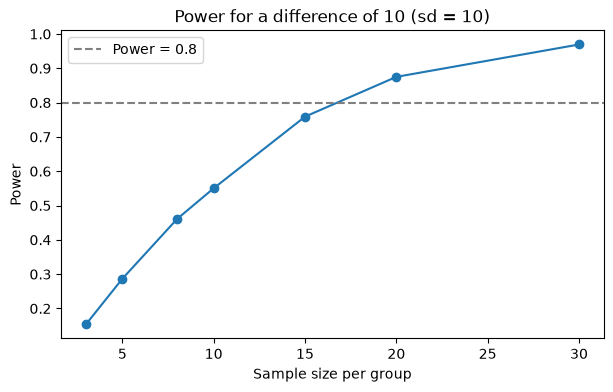

In [3]:
ns = [3, 5, 8, 10, 15, 20, 30]
powers = [rejection_rate(10, n) for n in ns]
for n, pw in zip(ns, powers):
    print(f"n={n:3d} per group: power={pw:.3f}, beta={1 - pw:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(ns, powers, "o-")
plt.axhline(0.8, color="gray", linestyle="--", label="Power = 0.8")
plt.xlabel("Sample size per group")
plt.ylabel("Power")
plt.title("Power for a difference of 10 (sd = 10)")
plt.legend()
plt.show()

## 3. The $\alpha$-$\beta$ trade-off (z-test, analytic)

For $H_0:\mu=100$, true $\mu=105$, $\sigma=15$, $n=36$ (so $SE=2.5$), the two-sided power is the probability that $\bar x$ falls in the rejection region when the mean is 105.

In [4]:
mu0, mu1, sigma, n = 100, 105, 15, 36
se = sigma / np.sqrt(n)

def power_two_sided(alpha):
    zc = stats.norm.ppf(1 - alpha / 2)
    upper = mu0 + zc * se
    lower = mu0 - zc * se
    return stats.norm.sf((upper - mu1) / se) + stats.norm.cdf((lower - mu1) / se)

alphas = [0.001, 0.01, 0.05, 0.10, 0.20]
for a in alphas:
    print(f"alpha={a:5.3f}: power={power_two_sided(a):.3f}, beta={1 - power_two_sided(a):.3f}")

one_sided = stats.norm.sf((mu0 + stats.norm.ppf(0.95) * se - mu1) / se)
print(f"One-sided power at alpha=0.05: {one_sided:.3f}")

alpha=0.001: power=0.098, beta=0.902
alpha=0.010: power=0.282, beta=0.718
alpha=0.050: power=0.516, beta=0.484
alpha=0.100: power=0.639, beta=0.361
alpha=0.200: power=0.764, beta=0.236
One-sided power at alpha=0.05: 0.639


Lowering $\alpha$ reduces false positives but increases $\beta$. The one-sided test has more power for an effect in the stated direction, at the price of ignoring the other direction.

## 4. Visualizing the two error regions

The left curve is the null distribution of $\bar x$, the right curve is the alternative. The threshold splits them: the area of the null to the right is $\alpha$, the area of the alternative to the left is $\beta$ (one-sided test).

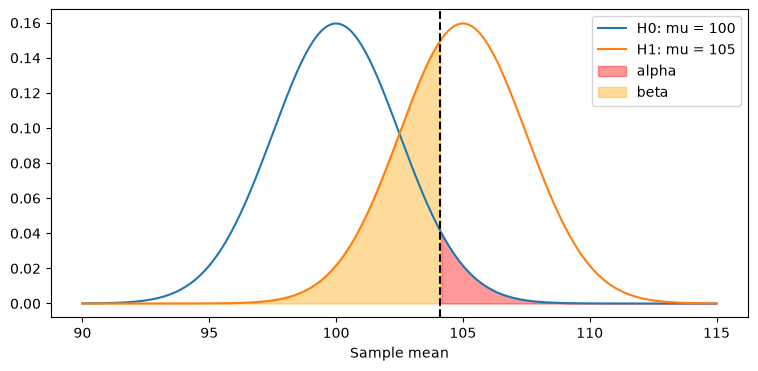

In [5]:
x = np.linspace(90, 115, 600)
crit = mu0 + stats.norm.ppf(0.95) * se
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(x, stats.norm.pdf(x, mu0, se), label="H0: mu = 100")
ax.plot(x, stats.norm.pdf(x, mu1, se), label="H1: mu = 105")
ax.fill_between(x[x >= crit], stats.norm.pdf(x[x >= crit], mu0, se), color="red", alpha=0.4, label="alpha")
ax.fill_between(x[x <= crit], stats.norm.pdf(x[x <= crit], mu1, se), color="orange", alpha=0.4, label="beta")
ax.axvline(crit, color="black", linestyle="--")
ax.set_xlabel("Sample mean")
ax.legend()
plt.show()

## 5. Required sample size

For a two-sample test, $n\approx 2\sigma^2(z_{1-\alpha/2}+z_{1-\beta})^2/\Delta^2$ per group. We verify by simulation that this achieves the target power.

In [6]:
sigma_, delta = 10, 4
n_req = int(np.ceil(2 * sigma_**2 * (stats.norm.ppf(0.975) + stats.norm.ppf(0.90)) ** 2 / delta**2))
print(f"Required n per group: {n_req}")
print(f"Simulated power at that n: {rejection_rate(delta, n_req, sd=sigma_, reps=4000):.3f}")

Required n per group: 132


Simulated power at that n: 0.898
